# Handcrafted features: audit and training projection

Prerequisite: run `build_features.py` with the pinned feature environment and the unchanged raw dataset. This executed notebook audits saved matrices and displays training-only diagnostics; it does not re-extract every image by default.

Version 1 uses 54 scalar/quality descriptors and 1,764 HOG values. Training-only preprocessing reduces the HOG block to 64 components, for 118 final inputs. Morphology quantities are documented display-composite proxies, not calibrated astronomical CAS/G-M20 measurements. No classifier is trained or evaluated here.

The code, features, plots, notebook and English record were produced with Codex assistance. Independent team confirmation is not recorded.

In [1]:
from pathlib import Path
from io import BytesIO
import sys, json, csv
import numpy as np
from PIL import Image as PILImage
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from validate_features import validate_artifacts
from galaxy_features import SCALAR_SCHEMA, make_preprocessor
summary = json.loads((ROOT / "metadata/features_v1/summary.json").read_text())
print({key: summary[key] for key in ["retained_rows", "scalar_dimensions", "hog_dimensions", "processed_dimensions", "training_fit_rows"]})

def show_figure(filename, width=1100):
    with PILImage.open(ROOT / "docs/features/figures" / filename) as image:
        preview = image.copy()
        preview.thumbnail((width, 1600), PILImage.Resampling.LANCZOS)
        buffer = BytesIO()
        preview.save(buffer, format="PNG", optimize=True)
    display(Image(data=buffer.getvalue()))

{'retained_rows': 17655, 'scalar_dimensions': 54, 'hog_dimensions': 1764, 'processed_dimensions': 118, 'training_fit_rows': 12359}


## Verify provenance and row alignment

The validator checks frozen IDs and labels, saved file hashes, scalar CSV/matrix agreement, training-only imputer/scaler statistics, PCA fit count, finite transformed exports, and disjoint partition membership. The CLI additionally re-extracts ten preselected training images. No held-out performance is evaluated.

In [2]:
verification = validate_artifacts(ROOT, check_images=False)
print(json.dumps(verification, indent=2))

{
  "status": "PASS",
  "retained_rows": 17655,
  "raw_dimensions": 1818,
  "processed_dimensions": 118,
  "partitions": {
    "train": [
      12359,
      118
    ],
    "validation": [
      2650,
      118
    ],
    "test": [
      2646,
      118
    ]
  },
  "fit_rows": 12359,
  "original_id_alignment_verified": true,
  "scalar_csv_matches_raw_matrix": true,
  "train_only_imputer_and_scaler_statistics_verified": true,
  "exported_transforms_reproduced": true,
  "finite_processed_matrices": true,
  "umap_training_rows_verified": true,
  "sampled_images_reextracted": 0,
  "source_and_artifact_hashes_verified": true,
  "overlap": 0,
  "figures": 4
}


## Feature families and exported matrices

Each NPZ keeps `X`, `y` and `original_indices` separate. Labels and row IDs must never be model inputs. The scalar CSV also has `label`, `split` and `original_index` metadata columns; omit them from any numeric feature selection. UMAP labels only color the points.

In [3]:
from collections import Counter
print("Scalar families:", dict(Counter(row["group"] for row in SCALAR_SCHEMA)))
for split in ["train", "validation", "test"]:
    with np.load(ROOT / "data/processed/features_v1" / f"{split}_features.npz", allow_pickle=False) as data:
        print(split, data["X"].shape, "finite:", bool(np.isfinite(data["X"]).all()))
print("Example scalar names:", [row["name"] for row in SCALAR_SCHEMA[:12]])

Scalar families: {'color': 33, 'morphology_proxy': 15, 'quality_flag': 6}
train (12359, 118) finite: True
validation (2650, 118) finite: True
test (2646, 118) finite: True
Example scalar names: ['center_channel_0_mean', 'center_channel_0_std', 'center_channel_1_mean', 'center_channel_1_std', 'center_channel_2_mean', 'center_channel_2_std', 'center_difference_0_1_mean', 'center_difference_0_1_std', 'center_difference_1_2_mean', 'center_difference_1_2_std', 'center_difference_0_2_mean', 'center_difference_0_2_std']


## Quality flags and fixed HOG reduction

Undefined raw measurements remain missing and flagged; no row is removed. A training-fitted median rule fills them for numeric models. The 64 HOG components were fixed before viewing their explained variance. A quality flag or filled value does not make an undefined physical measurement valid.

| feature | training_missing_count | training_true_count |
| --- | --- | --- |
| flag_mask_at_boundary | 0 | 2082 |

HOG training variance retained: 0.4203086495399475


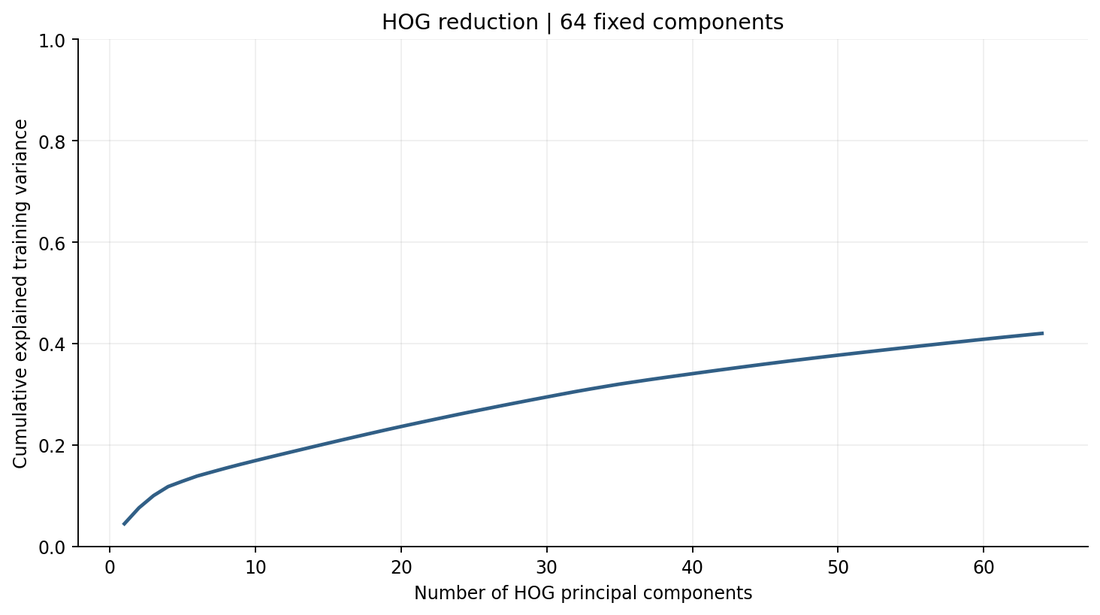

In [4]:
with (ROOT / "metadata/features_v1/training_quality.csv").open() as stream:
    quality = list(csv.DictReader(stream))
rows = [row for row in quality if int(row["training_missing_count"]) or int(row["training_true_count"])]
headers = ["feature", "training_missing_count", "training_true_count"]
table = "| " + " | ".join(headers) + " |\n| " + " | ".join(["---"] * len(headers)) + " |\n"
table += "\n".join("| " + " | ".join(row[key] for key in headers) + " |" for row in rows)
display(Markdown(table))
print("HOG training variance retained:", summary["hog_pca_explained_variance"])
show_figure("hog_pca_variance.png")

## Segmentation and raw morphology diagnostics

One prior seeded training example per class shows the implemented mask and moment center. This is an audit illustration, not ground-truth segmentation or evidence of uniformly reliable target detection. Boxes summarize finite raw training proxies before learned imputation/scaling; tails are hidden only in the drawing.

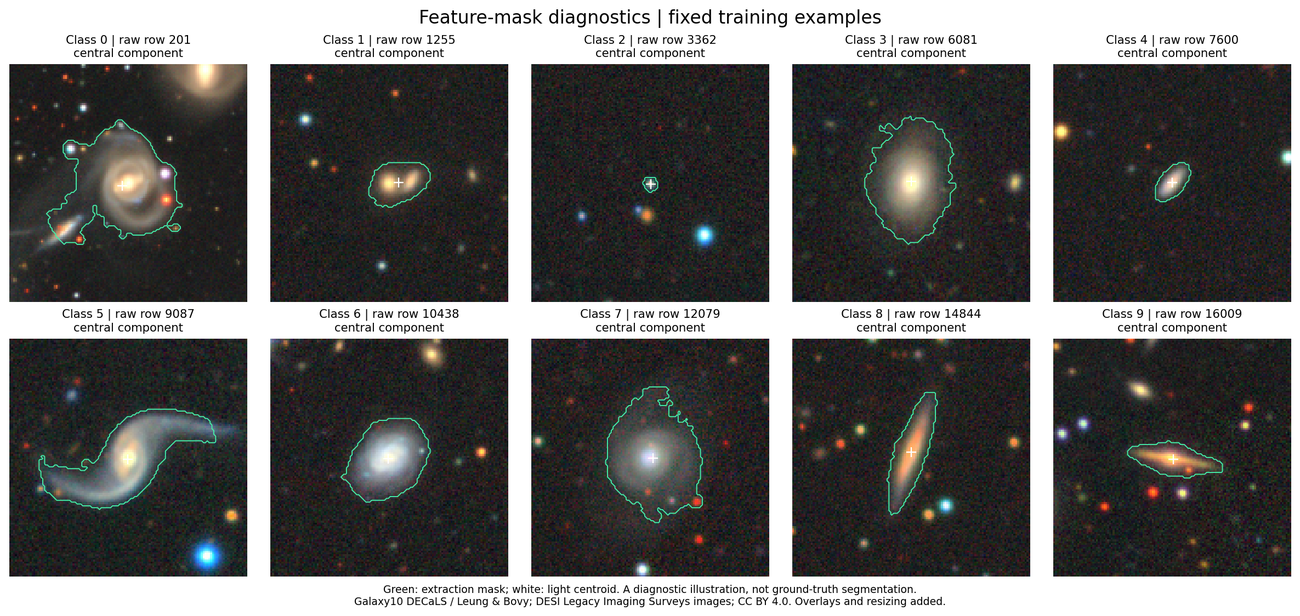

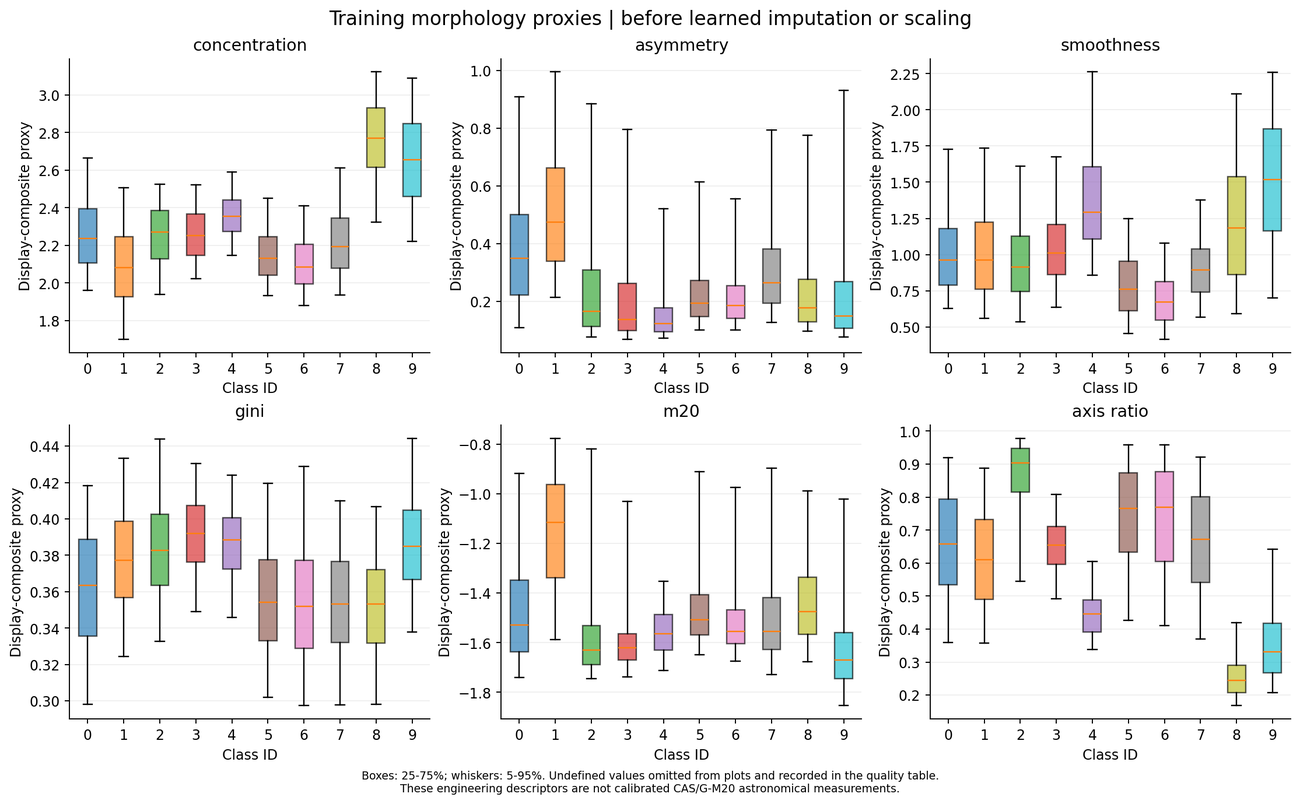

In [5]:
show_figure("training_segmentation_examples.png", width=1300)
show_figure("training_proxy_distributions.png", width=1300)

## Unsupervised training UMAP

UMAP uses processed training rows without labels, with seed 42, 15 neighbors, min_dist=0.1, 200 epochs and one worker. Colors are added after fitting. Islands, overlap and distances are descriptive properties of this projection, not classifier accuracy or a hypothesis test. Pretrained-representation comparisons belong to the later model module.

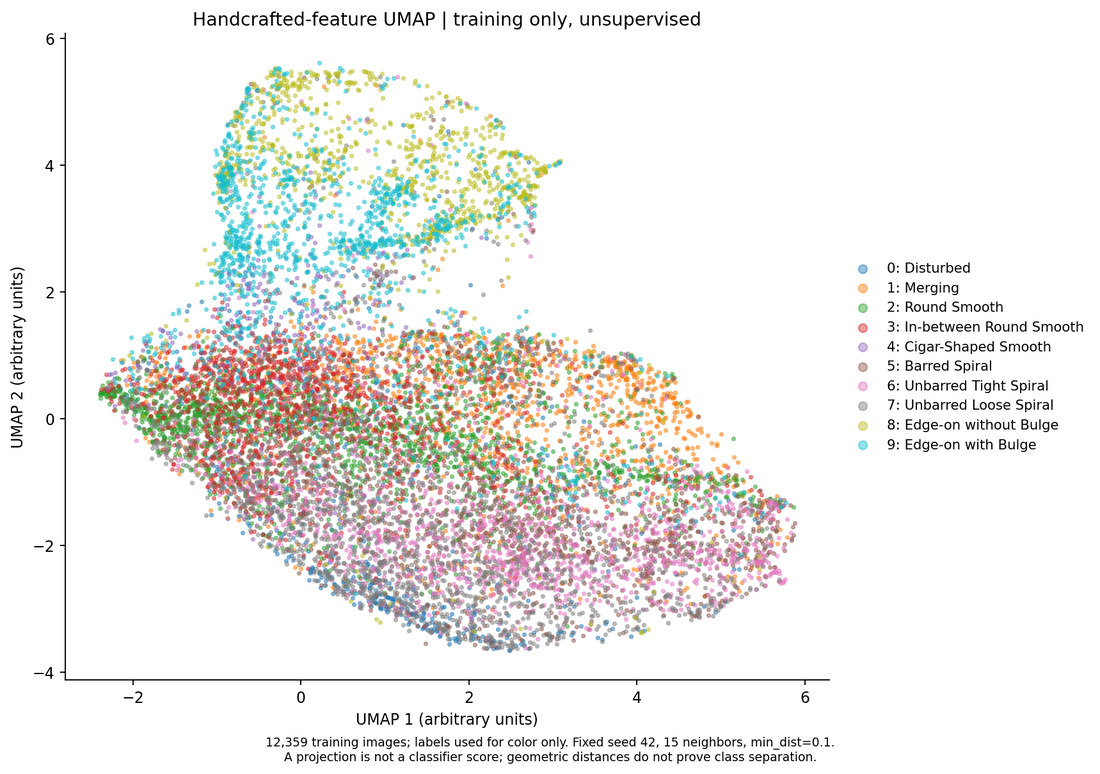

No classifier trained: True
No test score evaluated: True


In [6]:
show_figure("training_umap.png")
print("No classifier trained:", not summary["classifier_training_performed"])
print("No test score evaluated:", not summary["test_performance_evaluated"])

## Correct use in the next module

For future five-fold tuning, feed raw descriptors to `make_model_pipeline(estimator)` from `galaxy_features.py`, with the entire pipeline inside `GridSearchCV`. Imputation, scaling and PCA must be refitted inside each training fold. Do not cross-validate the already transformed full-training exports. The persisted full-training transform is for the eventual full-training model and held-out inference.

All formulas, conventions, sources, caveats and reproduction commands are in `docs/features/README.md`. Source images: Galaxy10 DECaLS (Leung & Bovy), DESI Legacy Imaging Surveys; labels: Galaxy Zoo; CC BY 4.0. Overlays, resizing, projection and aggregates are derived changes.